# 03 - Estado personalizado e múltiplos nós com LangGraph

Caso prático: um grafo que **recebe uma pergunta, classifica, processa e responde**.

```
START → classificar → (decisão) → processar_matematica
                                → processar_historia    → gerar_resposta → END
                                → processar_geral
```

- `classificar`: o LLM decide a categoria da pergunta.
- **Decisão condicional**: uma função lê a categoria e escolhe o nó de processamento.
- `processar_*`: cada nó prepara um material de apoio para a pergunta, com instruções diferentes.
- `gerar_resposta`: o LLM responde usando esse material.

Conceitos usados:

- **`TypedDict` / `MessagesState`**: o estado tem campos próprios e também a lista `messages`.
- **Reducer com `Annotated`**: `etapas` acumula o nome de cada nó que rodou, para registrar o caminho percorrido.
- **Arestas condicionais**: a escolha do próximo nó depende do estado.

## 1. Configuração

Igual aos outros notebooks: a chave e o modelo vêm do `.env` na raiz do projeto.

In [1]:
import operator
import os
from typing import Annotated

from dotenv import find_dotenv, load_dotenv
from IPython.display import Markdown, display
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, MessagesState, StateGraph
from IPython.display import Markdown, display
from IPython.display import Image

load_dotenv(find_dotenv())

llm = ChatOpenAI(
    model=os.getenv("OPENAI_MODEL", "gpt-5-mini"),
    api_key=os.getenv("OPENAI_API_KEY"),
)

In [2]:
def pedir(instrucao: str, conteudo: str) -> str:
    # Função auxiliar: envia uma instrução e um conteúdo ao LLM e devolve o texto da resposta.
    resposta = llm.invoke([SystemMessage(content=instrucao), HumanMessage(content=conteudo)])
    return resposta.content.strip()

## 2. Estado do grafo

- `pergunta`: texto que o usuário enviou (sobrescrito).
- `categoria`: resultado da classificação (sobrescrito).
- `contexto`: material produzido pelo nó de processamento (sobrescrito).
- `etapas`: lista de nomes de nós, **acumulada** com `operator.add`.
- `messages`: herdado de `MessagesState`, com o histórico da conversa.

In [3]:
class EstadoPergunta(MessagesState):
    pergunta: str
    categoria: str
    contexto: str
    etapas: Annotated[list[str], operator.add]


CATEGORIAS = ("matematica", "historia", "geral")

## 3. Nós

### Classificar

O LLM lê a pergunta e responde com uma única categoria. Se a resposta vier fora da lista, usamos `geral`.

In [4]:
def classificar(estado: EstadoPergunta) -> dict:
    texto = pedir(
        "Classifique a pergunta em uma das categorias: matematica, historia ou geral. "
        "Responda apenas com a palavra da categoria, em minúsculas.",
        estado["pergunta"],
    ).lower()
    categoria = texto if texto in CATEGORIAS else "geral"
    return {"categoria": categoria, "etapas": ["classificar"]}

### Processar

Cada categoria tem seu nó de processamento. Ele não responde ao usuário: só prepara o `contexto` para o nó de resposta.

In [5]:
def processar_matematica(estado: EstadoPergunta) -> dict:
    contexto = pedir(
        "Resolva a pergunta passo a passo, em no máximo 5 linhas curtas.",
        estado["pergunta"],
    )
    return {"contexto": contexto, "etapas": ["processar_matematica"]}


def processar_historia(estado: EstadoPergunta) -> dict:
    contexto = pedir(
        "Liste até 3 fatos históricos relevantes para a pergunta, em tópicos curtos.",
        estado["pergunta"],
    )
    return {"contexto": contexto, "etapas": ["processar_historia"]}


def processar_geral(estado: EstadoPergunta) -> dict:
    contexto = pedir(
        "Liste até 3 informações relevantes para responder a pergunta, em tópicos curtos.",
        estado["pergunta"],
    )
    return {"contexto": contexto, "etapas": ["processar_geral"]}

### Gerar resposta

O LLM escreve a resposta final com base na pergunta e no material. A resposta entra em `messages` com o reducer `add_messages`, que adiciona à lista.

In [6]:
def gerar_resposta(estado: EstadoPergunta) -> dict:
    texto = pedir(
        "Responda à pergunta em português, de forma clara e curta, usando o material de apoio.",
        f"Pergunta: {estado['pergunta']}\n\nMaterial de apoio:\n{estado['contexto']}",
    )
    return {"messages": [AIMessage(content=texto)], "etapas": ["gerar_resposta"]}

## 4. Montando o grafo

A aresta condicional lê `categoria` e devolve o nome do nó de processamento a seguir.

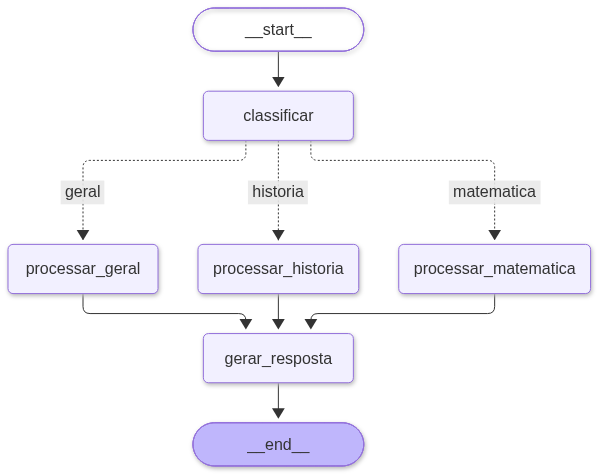

In [10]:
def escolher_processamento(estado: EstadoPergunta) -> str:
    return estado["categoria"]


grafo = StateGraph(EstadoPergunta)
grafo.add_node("classificar", classificar)
grafo.add_node("processar_matematica", processar_matematica)
grafo.add_node("processar_historia", processar_historia)
grafo.add_node("processar_geral", processar_geral)
grafo.add_node("gerar_resposta", gerar_resposta)

grafo.add_edge(START, "classificar")
grafo.add_conditional_edges(
    "classificar",
    escolher_processamento,
    {
        "matematica": "processar_matematica",
        "historia": "processar_historia",
        "geral": "processar_geral",
    },
)
grafo.add_edge("processar_matematica", "gerar_resposta")
grafo.add_edge("processar_historia", "gerar_resposta")
grafo.add_edge("processar_geral", "gerar_resposta")
grafo.add_edge("gerar_resposta", END)

app = grafo.compile()

display(Image(app.get_graph().draw_mermaid_png()))

## 5. Executando

Três perguntas de categorias diferentes. Cada uma segue um caminho diferente pelo grafo, e `etapas` mostra o caminho percorrido.

In [8]:
perguntas = [
    "Quanto é 15% de 240?",
    "Quem descobriu o Brasil?",
    "Por que o céu é azul?",
]

for pergunta in perguntas:
    estado = app.invoke({"pergunta": pergunta, "messages": [("user", pergunta)]})
    display(Markdown(
        f"**Pergunta:** {estado['pergunta']}\n\n"
        f"**Categoria:** {estado['categoria']}\n\n"
        f"**Caminho:** {' → '.join(estado['etapas'])}\n\n"
        f"**Resposta:** {estado['messages'][-1].content}"
    ))

**Pergunta:** Quanto é 15% de 240?

**Categoria:** matematica

**Caminho:** classificar → processar_matematica → gerar_resposta

**Resposta:** 15% = 0,15.  
0,15 × 240 = 36.  
Portanto, 15% de 240 é 36.

**Pergunta:** Quem descobriu o Brasil?

**Categoria:** historia

**Caminho:** classificar → processar_historia → gerar_resposta

**Resposta:** O território já era habitado por povos indígenas há milhares de anos. Entre os europeus, Pedro Álvares Cabral, que chegou ao litoral em 22 de abril de 1500, é geralmente considerado o descobridor do Brasil; houve outros contatos próximos (ex.: Vicente Yáñez Pinzón) e o Tratado de Tordesillas (1494) influenciou a posse colonial.

**Pergunta:** Por que o céu é azul?

**Categoria:** geral

**Caminho:** classificar → processar_geral → gerar_resposta

**Resposta:** Porque a luz solar é branca (mistura de cores) e, ao atravessar a atmosfera, é espalhada pelas moléculas do ar por espalhamento de Rayleigh, que favorece comprimentos de onda curtos: intensidade ∝ 1/λ^4. Assim o azul (menor λ) é espalhado muito mais e chega a nós de toda a parte do céu. Ao nascer/por do sol a luz percorre mais atmosfera, o azul é quase todo espalhado para fora do feixe direto, ficando principalmente os vermelhos e alaranjados.

## 6. Acompanhando nó a nó

Com `stream_mode="updates"`, vemos o que cada nó devolveu, em ordem.

In [9]:
for evento in app.stream(
    {"pergunta": "Quem descobriu o Brasil?", "messages": [("user", "Quem descobriu o Brasil?")]},
    stream_mode="updates",
):
    for nome_no, atualizacao in evento.items():
        print(f"[{nome_no}]")
        for campo, valor in atualizacao.items():
            if campo == "messages":
                valor = [m.content for m in valor]
            print(f"    {campo}: {valor}")

[classificar]
    categoria: historia
    etapas: ['classificar']
[processar_historia]
    contexto: - Pedro Álvares Cabral liderou a expedição portuguesa que chegou ao litoral em 22 de abril de 1500 e reivindicou as terras para Portugal.  
- A chegada aconteceu no contexto do Tratado de Tordesilhas (1494), que dividiu entre Espanha e Portugal as novas terras fora da Europa.  
- Povos indígenas habitavam o território muito antes da chegada europeia, por isso o termo "descoberta" é eurocêntrico.
    etapas: ['processar_historia']
[gerar_resposta]
    messages: ['Tradicionalmente atribui‑se a Pedro Álvares Cabral, que liderou a expedição que chegou ao litoral em 22 de abril de 1500 e reivindicou as terras para Portugal no contexto do Tratado de Tordesilhas (1494). Porém, povos indígenas já viviam nessas terras muito antes, por isso o termo "descoberta" é eurocêntrico.']
    etapas: ['gerar_resposta']


## Observações

- Um nó devolve só os campos que muda. Os outros continuam com o valor anterior.
- Campo sem `Annotated` é **substituído**. Com `Annotated[tipo, operator.add]`, os valores são **acumulados**.
- `MessagesState` já vem com `messages` e um reducer que adiciona mensagens.
- A decisão condicional é uma função que lê o estado e devolve o nome do próximo nó.
- A função `pedir` evita repetir a chamada ao LLM em cada nó. Ela é só uma função Python, não faz parte do LangGraph.